# Laboratory 2 - Quantization: PTQ and QAT

In Laboratory 1 we estimated the size of a model as *parameters x bytes per parameter*, and we noted that going from float32 to int8 makes the model 4 times smaller without touching the architecture. We promised to come back to this under the name **quantization**, and this is that laboratory. We take the same `SmallCNN` on CIFAR-10, with its 34,058 parameters and 133 KB of float32 weights, and find out how few bits per number it really needs, and what that costs in accuracy.

Plan:

0. Setup
1. Recap and the float baseline
2. Quantization basics: round, scale, zero-point
3. Post-training quantization (PTQ)
4. Quantization-aware training (QAT)
5. Results, exercises, questions
6. Optional: integer-only arithmetic

Everything is written in plain PyTorch, without any quantization library. Libraries such as Brevitas, TensorFlow Lite or Vitis AI do the same things for you, and we will meet some of them later in the course. Writing it by hand once is the best way to understand what they actually do.

**How to work.** Complete the cells marked `# TODO`. Most of them are one or two lines, and the text right above each cell tells you what is needed, so read it first. Keep in mind that the code is not the point here: after the class you will be asked about the theory and about your own results. The **Question** boxes are there for that, so try to answer each one before you run the next cell.

**What you should already know:** everything from Laboratory 1: the PyTorch training loop, `SmallCNN` on CIFAR-10, and how to estimate the size of a model from its number of parameters.

**What you will be able to do after this notebook:** explain what the scale and the zero-point are and compute them for a given range, fold batch normalization into a convolution, quantize the weights and activations of a trained network and calibrate it (PTQ), train a network with quantization switched on using the straight-through estimator (QAT), and decide which of the two methods a given situation calls for.

## 0. Setup

Use the **same environment as in Laboratory 1**. Nothing new is installed.

```
conda activate embedded-ai          # conda
source .venv/bin/activate           # venv, Linux / macOS
.venv\Scripts\activate              # venv, Windows
```

Put the notebook in the same folder as Laboratory 1, then the `data` folder is reused.

In [9]:
import copy
import os
import struct
import zipfile

import torch
import torchvision
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

print("torch version:", torch.__version__)
print("torchvision version:", torchvision.__version__)

device = "mps" if torch.backends.mps.is_available() else "cpu"
print("Using device:", device)


torch.manual_seed(0)

torch version: 2.13.0
torchvision version: 0.28.0
Using device: mps


## 1. Recap and the float baseline

The data, the model, `evaluate` and `train` are copied from Laboratory 1 without changes, so there is nothing new until Section 1.3.

### 1.1 Data

In [10]:
data_dir = "data"
if not os.path.isdir(os.path.join(data_dir, "cifar-10-batches-py")):
    print("CIFAR-10 not found locally, downloading...")
    import gdown
    zip_path = "cifar10.zip"
    gdown.download(id="1b7UF-Wu6aiOUhy4W2Yl9_1cO4SSApAPn", output=zip_path, quiet=False)
    with zipfile.ZipFile(zip_path) as zf:
        zf.extractall(".")
    os.remove(zip_path)
else:
    print("CIFAR-10 already present locally, skipping download.")

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)),
])

train_set = datasets.CIFAR10("data", train=True, download=True, transform=transform)
test_set = datasets.CIFAR10("data", train=False, download=True, transform=transform)

train_loader = DataLoader(train_set, batch_size=128, shuffle=True)
test_loader = DataLoader(test_set, batch_size=1000)

print("Training images:", len(train_set))
print("Test images:", len(test_set))

CIFAR-10 already present locally, skipping download.
Training images: 50000
Test images: 10000


### 1.2 Model, evaluation and training

In [11]:
def conv_block(in_channels, out_channels):
    # One building block: conv -> batch norm -> ReLU -> downsample by 2
    return [
        nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(),
        nn.MaxPool2d(2),
    ]


class SmallCNN(nn.Module):
    def __init__(self, width=16):
        super().__init__()
        self.features = nn.Sequential(
            *conv_block(3, width),
            *conv_block(width, 2 * width),
            *conv_block(2 * width, 4 * width),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(4 * width * 4 * 4, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


def evaluate(model, loader):
    # Returns the accuracy of the model on the given data
    model.eval()
    correct = 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            correct += (model(images).argmax(dim=1) == labels).sum().item()
    return correct / len(loader.dataset)


def train(model, epochs, lr=1e-3):
    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    for epoch in range(epochs):
        model.train()
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)                    # forward pass
            loss = F.cross_entropy(outputs, labels)    # loss

            optimizer.zero_grad()
            loss.backward()                            # backward pass
            optimizer.step()                           # weight update

        print(f"epoch {epoch + 1}/{epochs}  last batch loss: {loss.item():.3f}  "
              f"test accuracy: {evaluate(model, test_loader):.3f}")

### 1.3 The baseline, saved twice

We train `SmallCNN` for 10 epochs and save the weights after **5** and after **10** epochs. In this laboratory we will try two different approaches: Post-Training Quantisation and Quantisation Aware Training.

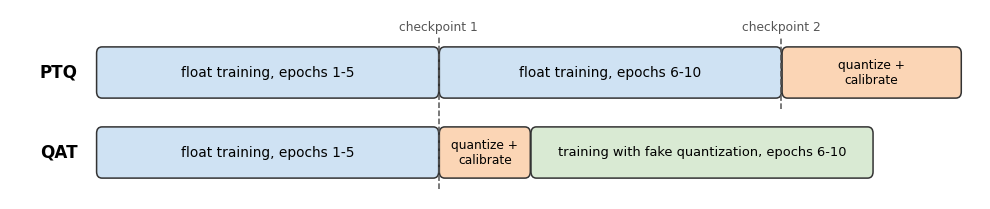

The two checkpoints are there to make the comparison in Section 4 fair. PTQ takes the finished 10-epoch model and quantizes it. QAT starts from the 5-epoch model and spends the remaining 5 epochs training with quantization switched on. Both methods get the same budget of 10 epochs, so any difference between them comes from the method and not from extra training.

Weights are saved and loaded through the `state_dict`, a dictionary with all parameters of a model:

```
torch.save(model.state_dict(), path)
model.load_state_dict(torch.load(path))
```

The cell skips the training if both files exist. Start it now and read Section 2 while it runs.

In [12]:
EPOCHS_FIRST = 5     # first checkpoint, the starting point for QAT
EPOCHS_TOTAL = 10    # second checkpoint, the model used for PTQ
CKPT_FIRST = "smallcnn_fp_epoch5.pth"
CKPT_FINAL = "smallcnn_fp_epoch10.pth"

if not (os.path.exists(CKPT_FIRST) and os.path.exists(CKPT_FINAL)):
    torch.manual_seed(1)
    fp_model = SmallCNN(width=16)

    train(fp_model, epochs=EPOCHS_FIRST)
    # TODO (student): save the weights to CKPT_FIRST
    torch.save(fp_model.state_dict(), CKPT_FIRST)

    train(fp_model, epochs=EPOCHS_TOTAL - EPOCHS_FIRST)
    # TODO (student): save the weights to CKPT_FINAL
    torch.save(fp_model.state_dict(), CKPT_FINAL)

else:
    print("Checkpoints found, skipping training.")


def load_fp(path):
    # Returns a float SmallCNN with the weights from the given checkpoint
    model = SmallCNN(width=16)
    model.load_state_dict(torch.load(path, map_location=device))
    return model.to(device).eval()


fp_first_acc = evaluate(load_fp(CKPT_FIRST), test_loader)
fp_final_acc = evaluate(load_fp(CKPT_FINAL), test_loader)
print(f"Float model after {EPOCHS_FIRST} epochs:  {fp_first_acc:.4f}")
print(f"Float model after {EPOCHS_TOTAL} epochs: {fp_final_acc:.4f}")

epoch 1/5  last batch loss: 0.868  test accuracy: 0.621
epoch 2/5  last batch loss: 0.888  test accuracy: 0.671
epoch 3/5  last batch loss: 0.611  test accuracy: 0.701
epoch 4/5  last batch loss: 0.958  test accuracy: 0.721
epoch 5/5  last batch loss: 0.682  test accuracy: 0.732
epoch 1/5  last batch loss: 0.749  test accuracy: 0.729
epoch 2/5  last batch loss: 0.682  test accuracy: 0.731
epoch 3/5  last batch loss: 0.515  test accuracy: 0.739
epoch 4/5  last batch loss: 0.671  test accuracy: 0.746
epoch 5/5  last batch loss: 0.409  test accuracy: 0.751
Float model after 5 epochs:  0.7319
Float model after 10 epochs: 0.7513


## 2. Quantization basics

### 2.1 Why quantize

**Quantization** replaces 32-bit floating point numbers with lower precition representations (e.g. integer of 8 bits or fewer). Three reasons to do it on an embedded device:

- **Memory.** Fewer bits per weight means less flash, and fewer bits per activation means less RAM. This is the argument from Laboratory 1.
- **Speed and energy.** Integer arithmetic is cheaper than floating point arithmetic. Less data also has to be moved between memory and the processor, and moving data is a large part of the energy bill.
- **Hardware.** Many small microcontrollers have no floating point unit at all, so every float operation is emulated in software and is very slow. On an FPGA the size of a multiplier grows quickly with the bit width, so a 4-bit network can be several times smaller than an 8-bit one.

The price is precision. This laboratory is about paying as little of it as possible.

### 2.2 Number representations

**Unsigned integer.** Bits are powers of two: `1011b = 8 + 0 + 2 + 1 = 11`. With `b` bits: `0 ... 2^b - 1`.

**Signed integer (two's complement).** The top bit has a negative weight: `1011b = -8 + 0 + 2 + 1 = -5`. With `b` bits: `-2^(b-1) ... 2^(b-1) - 1`.

**Fixed point.** An integer with an agreed position of the binary point.

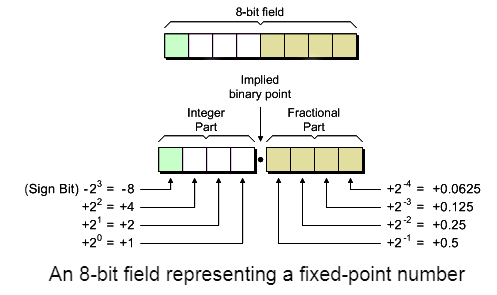

With 4 integer and 4 fraction bits, as in the figure, the bits `1011.0100` stand for `-8 + 2 + 1 + 0.25 = -4.75`. The hardware, however, stores and processes a plain integer, here `-76`. The position of the point, that is the instruction "divide by `2^4`", exists only in the head of the programmer. The distance between two neighbouring values is the same everywhere, here `1/16`.

**Floating point (float32, IEEE 754).** Sign `S`, exponent `E` and fraction `F`, with the value `(-1)^S * 1.F * 2^(E - 127)`.

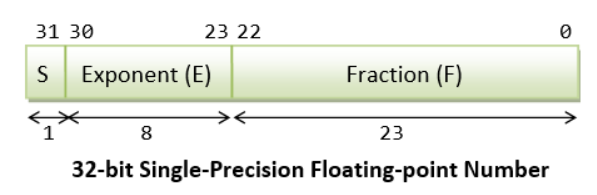

The exponent moves the binary point, which is why the point is said to "float". Thanks to this the format covers values from about `1e-38` to `1e38`, but the distance between two neighbouring values is no longer constant: it grows with the magnitude of the number.

Why does this matter for neural networks?

- Floating point is expensive in hardware. To add two floats you have to compare the exponents, shift one of the fractions, add, normalize the result and round it. Adding two integers takes a single adder.
- The huge range of float32 is wasted on a network. The weights of one layer sit in a narrow range that we know in advance, such as `[-0.5, 0.5]`, and the activations of a layer are similarly well behaved. We do not need 38 orders of magnitude, we need a few hundred evenly spaced values in the right place.

That is exactly what fixed point offers: the number is stored as a plain **integer**, and a **constant factor** (here `2^-4`) says how much one unit of that integer is worth. The factor is not stored with the number, so the hardware only ever works with integers.

In the rest of this laboratory we do the same thing: everything we store is an integer. The only difference is how the integer is turned back into a real value. Fixed point allows only a power of two as the factor, and its grid always starts at zero. Quantization of neural networks lifts both restrictions, and you will build both extensions yourself in Sections 2.4 and 2.5.

Fill in the two marked lines.

In [ ]:
def float32_bits(x):
    bits = f"{struct.unpack('>I', struct.pack('>f', x))[0]:032b}"
    return f"{bits[0]} {bits[1:9]} {bits[9:]}"


print("float32: sign | exponent | fraction")
for value in [1.0, -4.75, 0.1]:
    print(f"{value:>8}: {float32_bits(value)}")

# The 8 bits 1011.0100 from the fixed point figure, read as a signed integer:
stored_integer = -76

# TODO (student): which real value do these bits stand for, with 4 fraction bits?
value = stored_integer / 2**4

# TODO (student): how many different values can 8 bits store? And 4 bits?
levels_8, levels_4 = 2 ** 8, 2 ** 4

print(f"\nfixed point 1011.0100 = {value}")
print(f"8 bits: {levels_8} values, 4 bits: {levels_4} values")

float32: sign | exponent | fraction
     1.0: 0 01111111 00000000000000000000000
   -4.75: 1 10000001 00110000000000000000000
     0.1: 0 01111011 10011001100110011001101

fixed point 1011.0100 = -4.75
8 bits: 256 values, 4 bits: 16 values


Look at `0.1` in float32: its fraction is a repeating pattern that simply gets cut off, so even float32 does not store `0.1` exactly. Every number format with a finite number of bits is a quantization of the real numbers. The only question is how coarse it is.

### 2.3 Step 1: round and clamp

We start with the simplest possible quantizer. We want to store real values as 4-bit unsigned integers, so the only values available are `0, 1, ..., 15`. Every real value has to be moved to the nearest one of them, and values beyond the ends have to be moved to the nearest end.

Two PyTorch functions do exactly that:

- `torch.round(x)` rounds every element to the nearest whole number,
- `torch.clamp(x, lo, hi)` limits every element to `[lo, hi]`: smaller values become `lo`, larger ones become `hi`.

The result stays a float32 tensor. That is fine, what matters is that it only holds values that *could* be stored in 4 bits.

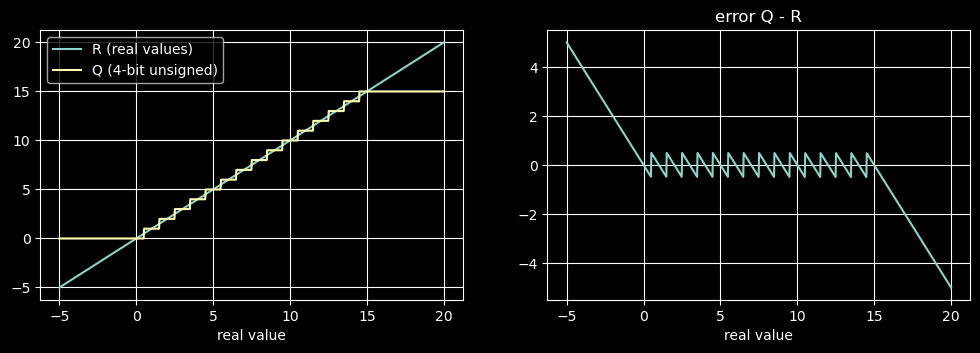

In [18]:
R = torch.linspace(-5, 20, 1000)     # 1000 evenly spaced values from -2 to 18

# TODO (student): quantize R to 4-bit unsigned integers
Q = torch.clamp(torch.round(R), 0, 15)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].plot(R, R, label="R (real values)")
axes[0].plot(R, Q, label="Q (4-bit unsigned)")
axes[0].set_xlabel("real value")
axes[0].legend()
axes[0].grid()
axes[1].plot(R, Q - R)
axes[1].set_xlabel("real value")
axes[1].set_title("error Q - R")
axes[1].grid()
plt.show()

The plot on the right shows the two kinds of error that every quantizer has. They will follow us through the whole laboratory:

- **Rounding error**, inside the range. It is a sawtooth between `-0.5` and `0.5`, so it is at most half of the distance between two neighbouring integers.
- **Clipping error**, outside the range. It has no limit: the further a value lies outside the range, the larger the error.

> **Question.** What would the rounding error look like with `torch.floor` instead of `torch.round`? Why is that worse when thousands of such errors are added up in a layer?

### 2.4 Step 2: the scale

Now data that looks like the weights of a network: 1000 values between 0 and 1.

In [21]:
R = torch.linspace(0, 1, 1000)

# TODO (student): quantize R to 4-bit unsigned integers
Q = torch.clamp(torch.round(R * 15), 0, 15)

print("different values in Q:", Q.unique().tolist())      # .unique() returns each value once

different values in Q: [0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 13.0, 14.0, 15.0]


Only 2 of the 16 available integers are used: everything below 0.5 became 0 and the rest became 1, so almost all of the information in the data is lost. For data between 0 and 1000 the opposite would happen, and nearly everything would be clipped to 15.

The problem is a mismatch of spacing. Neighbouring integers are 1 apart, while the whole data set is only 1 wide, so it fits between two of them. The 16 integers should instead be spread evenly over the range of the data: the integer `0` stands for the smallest value, the integer `15` for the largest, and the integers in between for equally spaced values in between.

The distance between the values of two neighbouring integers is called the **scale**, `S`. It is the real value that one integer step is worth. The stored integer then no longer means "the value q" but "q steps of size `S`".

The size of the step follows from the data and from the integer type. From the integer `0` to the integer `15` there are 15 steps, and together they have to cover the data from its smallest to its largest value. The width of the data and the number of steps therefore determine the size of one step.

Think of the integers `0 ... 15` as a ruler with 16 marks. From the first mark to the last there are 15 steps. Put the first mark on the smallest value in the data and the last mark on the largest one. The 15 steps together now span the whole width of the data, so the width of the data and the number of steps tell you the size of one step.

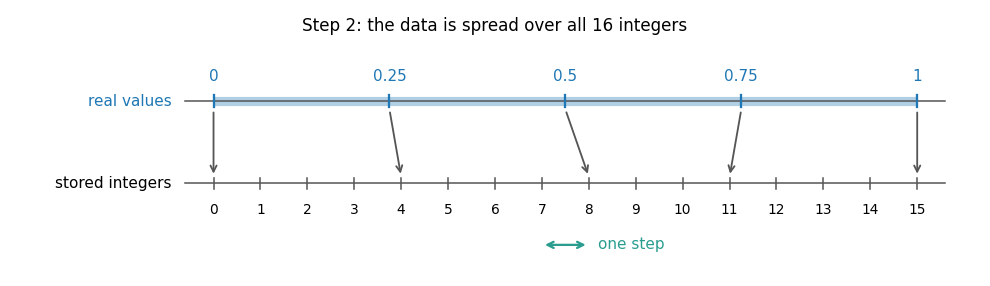

Then:

- **to quantize a value**, count how many steps fit in it. That is usually not a whole number, so round it, and clamp it as in Step 1.
- **to get a real value back**, take the stored number of steps and multiply by the size of one step.

Using the defined distribution of real values R, and 4 bit integer calculate the step, and then quantise, and requantize

scale S = 0.06667
integers used: 0 ... 15 (16 different values)
largest error |R_hat - R|: 0.03323   (half a step = 0.03333)


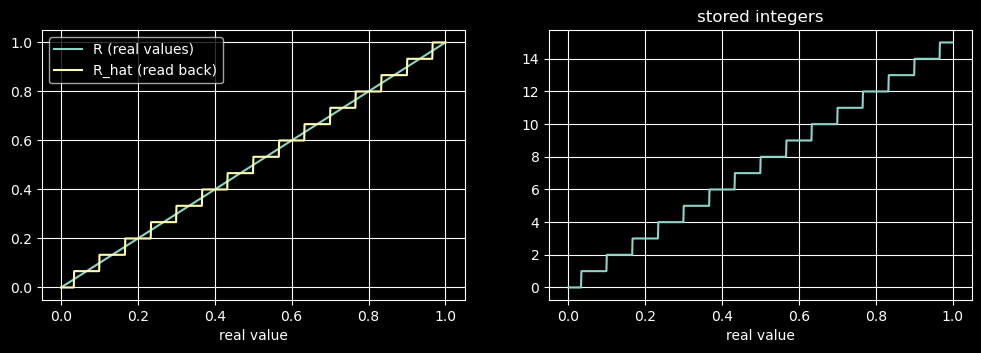

In [ ]:
qmin, qmax = 0, 15
data_min, data_max = 0.0, 1.0

# TODO (student): 1. data_width: how wide is the data, from its smallest to its largest value?
#                 2. num_steps:  how many steps are there from the lowest to the highest integer?
#                 3. scale:      the size of one step
#                 4. Q:          quantize R to integers in [qmin, qmax]
#                 5. R_hat:      read Q back as real values
data_width = data_max - data_min
num_steps = qmax - qmin
scale = data_width / num_steps
Q = torch.clamp(torch.round(R / scale), qmin, qmax)
R_hat = Q * scale

print(f"scale S = {float(scale):.5f}")
print(f"integers used: {int(Q.min())} ... {int(Q.max())} ({len(Q.unique())} different values)")
print(f"largest error |R_hat - R|: {(R_hat - R).abs().max().item():.5f}   (half a step = {float(scale) / 2:.5f})")

assert Q.min() == 0 and Q.max() == 15 and len(Q.unique()) == 16, "All 16 integers should be in use."
assert (R_hat - R).abs().max() <= float(scale) / 2 + 1e-6, "The error can never be larger than half a step."

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].plot(R, R, label="R (real values)")
axes[0].plot(R, R_hat, label="R_hat (read back)")
axes[0].set_xlabel("real value")
axes[0].legend()
axes[0].grid()
axes[1].plot(R, Q)
axes[1].set_xlabel("real value")
axes[1].set_title("stored integers")
axes[1].grid()
plt.show()

Three names that come back in every section: `r` is the real value, `q` the stored integer, `r_hat` the real value read back from `q`. The difference `r_hat - r` is the quantization error, and inside the range it is at most half a step.

> **Question.** What happens to the step, and to the largest error, if you add one bit? And if the data is twice as wide?

> add 1 bit -> scale / 2, data * 2 wide -> scale * 2

Compare this with Section 2.2. Fixed point is this very scheme with one restriction: the step must be a power of two. That is attractive in hardware, because multiplying by a power of two is a bit shift. Here the step can be any real number, so the ruler ends exactly where the data ends. This is the first of the two extensions.

### 2.5 Step 3: the zero-point

New data, with negative values: from `-2.5` to `10`. Apply Step 2:

integers used: 0 ... 12 (13 different values)
scale S = 0.8333
the data needs the steps 0 ... 12, the integers we have are 0 ... 15


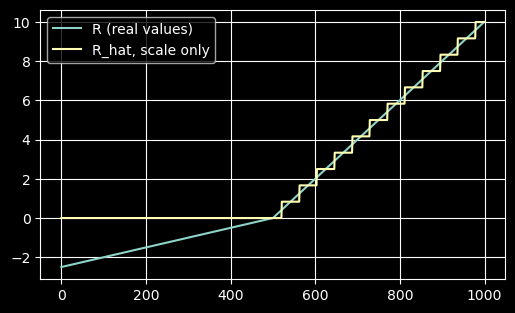

In [28]:
R4 = torch.cat([torch.linspace(-2.5, 0, 500), torch.linspace(0, 10, 500)])

# TODO (student): Reuse code from Step 2.
data_width = R4.max() - R4.min()
num_steps = qmax - qmin
scale = data_width / num_steps
Q = torch.clamp(torch.round(R4 / scale), qmin, qmax)
R_hat = Q * scale

print(f"integers used: {int(Q.min())} ... {int(Q.max())} ({len(Q.unique())} different values)")

steps = torch.arange(qmin, qmax + 1) * scale

print(f"scale S = {float(scale):.4f}")
print(f"the data needs the steps {int(steps.min())} ... {int(steps.max())}, the integers we have are {qmin} ... {qmax}")

plt.figure(figsize=(6, 3.5))
plt.plot(R4, label="R (real values)")
plt.plot(R_hat, label="R_hat, scale only")
plt.legend()
plt.grid()
plt.show()

The step size is right: 15 steps span the data. But the "ruler" lies in the wrong place. The data needs the steps `-3 ... 12`, and we can only store `0 ... 15`. The steps `-3, -2, -1` were clamped to 0, so all negative values are lost, and the integers `13, 14, 15` are never used.

The fix: **shift the "ruler"**. Add the same whole number to every step count, so that the step counts `-3 ... 12` become the integers `0 ... 15`. This number is the **zero-point**, `Z`.

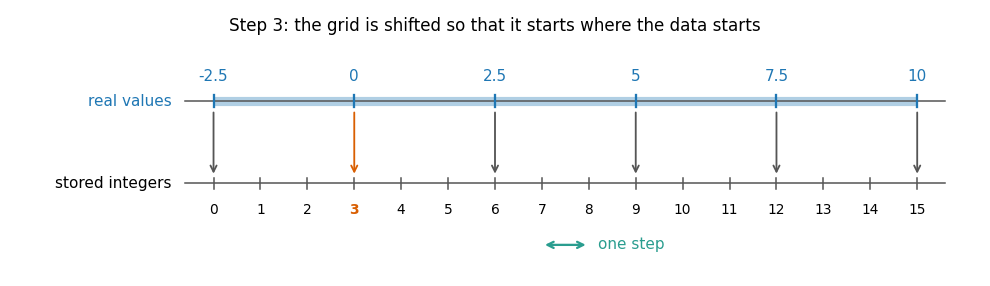

`Z` is found in two moves:

1. Express the **smallest value in the data** as a number of steps, exactly as in Step 2. Here `-2.5` is `-3` steps.
2. Ask what has to be added to that number to reach the **lowest integer we have**. Here the lowest integer is `0`, and to get from `-3` to `0` we add `3`. So `Z = 3`.

The same two moves work for any data and any integer type. If the smallest value were at `-7.4` steps and the lowest integer were `0`, the shift would be `7.4`, rounded to `Z = 7`, because `Z` has to be a whole number. If the smallest value were at `-20` steps and the integers were signed 8-bit, with `-128` as the lowest, we would have to add `-108` to get from `-20` to `-128`, so `Z = -108`.

The name says what `Z` is: the real value `0.0` is zero steps, so after the shift it is stored as the integer `Z`.

Now:

- **to quantize a value**: count the steps, round, add `Z`, clamp.
- **to get a real value back**: undo it in reverse order. Remove `Z`, then multiply by the size of one step.

Two rules:

- Because `Z` is a whole number, the real value `0.0` is stored **without any error**. A network is full of exact zeros (zero padding, the output of ReLU), so this matters.
- The range must contain zero. Data in `[2, 10]` is treated as `[0, 10]`.

scale S = 0.8333, zero-point Z = 3
integers used: 0 ... 15 (16 different values)
largest error: 0.4158   (half a step = 0.4167)


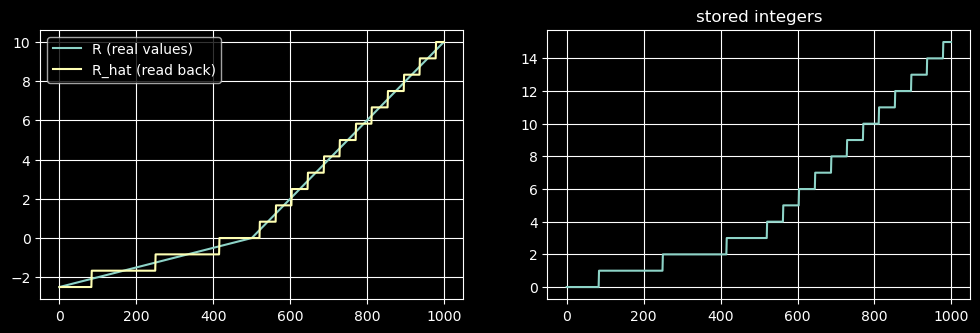

In [31]:
qmin, qmax = 0, 15

# TODO (student): 1. scale:      as in Step 2
#                 2. zero_point: the shift that moves the smallest value of the data onto qmin (a whole number)
#                 4. Q:          quantize R to integers in [qmin, qmax]
#                 4. R_hat:      read Q back as real values
# scale = same?
zero_point = -(R4.min() / scale)
Q = torch.clamp(torch.round(R4 / scale + zero_point), qmin, qmax)
R_hat = (Q - zero_point) * scale

print(f"scale S = {float(scale):.4f}, zero-point Z = {int(zero_point)}")
print(f"integers used: {int(Q.min())} ... {int(Q.max())} ({len(Q.unique())} different values)")
print(f"largest error: {(R_hat - R4).abs().max().item():.4f}   (half a step = {float(scale) / 2:.4f})")

assert int(zero_point) == 3, "Which integer should the real value 0.0 be stored as?"
assert Q.min() == 0 and Q.max() == 15 and len(Q.unique()) == 16, "All 16 integers should be in use."
assert (R_hat - R4).abs().max() <= float(scale) / 2 + 1e-6, "The error can never be larger than half a step."
assert R_hat[Q == zero_point].abs().max() == 0, "The real value 0.0 must be read back exactly."

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].plot(R4, label="R (real values)")
axes[0].plot(R_hat, label="R_hat (read back)")
axes[0].legend()
axes[0].grid()
axes[1].plot(Q)
axes[1].set_title("stored integers")
axes[1].grid()
plt.show()

A scale together with a zero-point is called **affine** quantization, and practically every framework uses it. The zero-point is the second extension over fixed point: the grid no longer has to start at zero, it can sit wherever the data is.

> **Question.** The output of a ReLU is never negative. What is its zero-point with unsigned integers?

> negative?

### 2.6 Functions for everything

Now pack Steps 2 and 3 into functions that we will use in the whole rest of the notebook. Two things become more general than in the examples above:

- **The integer type.** For a signed type the lowest integer is negative, for example `-128` for 8 bits. The rule does not change: the smallest value of the range lands on the lowest integer, the largest on the highest.
- **The range.** `r_min` and `r_max` are arguments. If the range does not contain zero, extend it.

`qrange` is given. `torch.as_tensor` turns a plain number into a tensor, so the functions accept both.

In [ ]:
def qrange(bits, signed):
    # The lowest and the highest integer of the given type
    if signed:
        return -(2 ** (bits - 1)), 2 ** (bits - 1) - 1
    return 0, 2 ** bits - 1


def compute_qparams(r_min, r_max, bits, signed=False):
    # Scale and zero-point that map the real range [r_min, r_max] onto the integers of the given type
    qmin, qmax = qrange(bits, signed)
    r_min = torch.as_tensor(r_min, dtype=torch.float32)
    r_max = torch.as_tensor(r_max, dtype=torch.float32)

    # TODO (student): 1. extend the range so that it contains zero (torch.clamp has the arguments min= and max=)
    #                 2. scale (keep it above 1e-8, so that we never divide by zero)
    #                 3. zero_point (a whole number, clamped to [qmin, qmax])
    # r_min = 
    # r_max = 
    # scale = 
    # zero_point = 
    return scale, zero_point


def quantize(r, scale, zero_point, qmin, qmax):
    # Real values -> integers (kept in a float tensor)
    # TODO (student)


def dequantize(q, scale, zero_point):
    # Integers -> the real values they stand for
    # TODO (student)


# 1. Step 3 again
s, z = compute_qparams(R4.min(), R4.max(), 4, signed=False)
assert int(z) == 3 and abs(float(s) - 12.5 / 15) < 1e-6

# 2. A signed type: the range [-1, 3] on 8 signed bits
s, z = compute_qparams(-1.0, 3.0, 8, signed=True)
print(f"range [-1, 3], 8 bits signed:   S = {float(s):.5f}, Z = {int(z)}")
assert int(z) == -64
assert quantize(torch.tensor(-1.0), s, z, -128, 127) == -128
assert quantize(torch.tensor(3.0), s, z, -128, 127) == 127
assert dequantize(quantize(torch.tensor(0.0), s, z, -128, 127), s, z) == 0

# 3. A range without zero is extended: [2, 10] becomes [0, 10]
s, z = compute_qparams(2.0, 10.0, 4, signed=False)
print(f"range [2, 10], 4 bits unsigned: S = {float(s):.5f}, Z = {int(z)}")
assert int(z) == 0 and abs(float(s) - 10 / 15) < 1e-6
print("All checks passed.")

**Fake quantization.** To measure how a network behaves after quantization, we do not need the integers themselves. We need the values the network would see. So we quantize and immediately dequantize:

```
real value  ->  integer  ->  real value on the grid
```

The result is still a float tensor, which is why it is called *fake*, but it only contains the few values that the chosen number of bits can represent. This lets us simulate an integer network on a GPU with ordinary float layers. We use it in all of Sections 3 and 4.

In the cell below, `*qrange(bits, signed=False)` unpacks the two returned numbers into the two arguments `qmin, qmax`.

In [ ]:
def fake_quantize(r, scale, zero_point, qmin, qmax):
    # TODO (student): quantize, then dequantize


plt.figure(figsize=(7, 3.5))
plt.plot(R4, label="real values", color="black", linewidth=1)
for bits in [6, 4, 2]:
    s, z = compute_qparams(R4.min(), R4.max(), bits, signed=False)
    R4_fq = fake_quantize(R4, s, z, *qrange(bits, signed=False))
    plt.plot(R4_fq, label=f"{bits} bits: {len(R4_fq.unique())} levels")
plt.legend()
plt.grid()
plt.show()

### 2.7 Rounding error against clipping error

So far the range always went from the smallest to the largest value of the data, so nothing was ever clipped. That sounds like the safe choice, but it is not always the best one. A wide range means a large step, and a large step means a larger rounding error for *every* value, only to accommodate a few extreme ones.

The data below has the shape of a typical activation after ReLU: many small values and a few large ones. For each clipping threshold `clip`, quantize the data to 4 bits with the range `[0, clip]`, so that everything above `clip` is clipped, and measure the mean squared error. `F.mse_loss(a, b)` returns the mean of `(a - b)^2`.

In [ ]:
torch.manual_seed(0)
x = torch.randn(100_000).abs()

bits = 4
qmin, qmax = qrange(bits, signed=False)
clip_values = torch.linspace(0.3, x.max().item(), 80)
mse = []
for clip in clip_values:
    # TODO (student): fake-quantize x with the range [0, clip] and append the mean squared error to mse

best = clip_values[torch.tensor(mse).argmin()].item()
print(f"largest value in the data: {x.max().item():.2f}")
print(f"best clipping threshold:   {best:.2f}")
print(f"MSE with the full range: {mse[-1]:.5f}, MSE with the best threshold: {min(mse):.5f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist(x.numpy(), bins=100)
axes[0].axvline(best, color="red", linestyle="--", label="best threshold")
axes[0].axvline(x.max().item(), color="gray", linestyle="--", label="largest value")
axes[0].set_title("the data")
axes[0].legend()
axes[1].plot(clip_values, mse)
axes[1].axvline(best, color="red", linestyle="--")
axes[1].set_xlabel("clipping threshold")
axes[1].set_ylabel("mean squared error")
axes[1].grid()
plt.show()

> **Question.** Why is the smallest error not at the full range? Which error dominates on the left of the minimum, and which on the right? Would the gap be larger or smaller with 8 bits?

Keep this picture in mind. Choosing the range is the most important decision in quantization, and PTQ and QAT are, to a large degree, two different ways of making it.

## 3. Post-training quantization (PTQ)

PTQ quantizes a network that is **already trained**, without training it any further. All it needs are the trained weights and a handful of example inputs: no labels, no optimizer, no GPU hours. That makes it the first thing to try, always.

We work with the 10-epoch model and go in small steps. First a single dot product, to see what a quantized layer computes. Then the weights, then batch norm, and finally the activations. Each step builds on the one before.

### 3.1 A dot product on integers

Every layer of a network, convolutional or linear, computes sums of products `w * x`. Suppose both the weights and the inputs are quantized. From your `dequantize` you know which real value each stored integer stands for:

```
w_hat = S_w * (q_w - Z_w)        x_hat = S_x * (q_x - Z_x)
```

so

```
sum( w_hat * x_hat ) = S_w * S_x * sum( (q_w - Z_w) * (q_x - Z_x) )
```

The scales are the same for all elements, so they can be pulled out of the sum, and everything that is left inside is an integer. The device can therefore compute the whole sum with integer multiplications and additions, and apply the two scales only once, at the very end.

Compute the integer sum below. `.to(torch.int32)` converts a tensor to real 32-bit integers.

In [ ]:
x = torch.tensor([0.2, -0.4, 0.7, -0.9])      # inputs
w = torch.tensor([0.5, -0.3, 0.1, -0.8])      # weights
y_float = (w * x).sum()

# 8-bit unsigned quantization of both
s_x, z_x = compute_qparams(x.min(), x.max(), 8)
s_w, z_w = compute_qparams(w.min(), w.max(), 8)
q_x = quantize(x, s_x, z_x, 0, 255).to(torch.int32)
q_w = quantize(w, s_w, z_w, 0, 255).to(torch.int32)
zi_x, zi_w = int(z_x), int(z_w)
print("q_x =", q_x.tolist(), " Z_x =", zi_x)
print("q_w =", q_w.tolist(), " Z_w =", zi_w)

# TODO (student): calculate the sum and y_integerfrom the formula above, using the integers q_w, q_x, zi_w, zi_x, and scales s_w, s_x
# accumulator = 
# y_integer = 

# The same dot product with fake quantization, in floats
y_fake = (fake_quantize(w, s_w, z_w, 0, 255) * fake_quantize(x, s_x, z_x, 0, 255)).sum()

print(f"\ninteger accumulator:      {accumulator.item()}")
print(f"float result:             {y_float.item():.6f}")
print(f"integer result, rescaled: {y_integer.item():.6f}")
print(f"fake-quantized result:    {y_fake.item():.6f}")
assert not accumulator.is_floating_point(), "The accumulator must be computed from the integer tensors."
assert abs(y_integer.item() - y_fake.item()) < 1e-5

The integer result and the fake-quantized result are the same number (up to float rounding in the last digits), and both are close to the float result. This is the justification for everything that follows: **a network with fake-quantized weights and activations behaves like the same network running on integers.** We can therefore measure the accuracy of an integer network on a GPU, with ordinary float layers.

Keep one detail in mind for Section 3.4: before every multiplication above, two subtractions are needed, `q_w - Z_w` and `q_x - Z_x`.

### 3.2 What can be quantized?

A dot product has only weights and inputs. A real network has more kinds of numbers, so before quantizing anything, take stock of what is there. `model.state_dict()` holds every tensor that is stored with the model, and `model.modules()` iterates over all of its layers.

> **Question (answer before running).** Which numbers does `SmallCNN` need at inference time? Which of them are stored in flash, and which exist only in RAM while an image is processed?

In [ ]:
fp_model = load_fp(CKPT_FINAL)

print(f"{'tensor':<34}{'shape':<18}{'numbers':>8}")
for name, tensor in fp_model.state_dict().items():
    if "num_batches_tracked" not in name:
        print(f"{name:<34}{str(tuple(tensor.shape)):<18}{tensor.numel():>8}")

# TODO (student): count the numbers in each group
#   n_weights: the weight tensors of all Conv2d and Linear layers
#   n_biases:  the bias tensors of all Conv2d and Linear layers
#   n_bn:      everything that belongs to the BatchNorm2d layers (weight, bias, running_mean, running_var)
# n_weights = 
# n_biases = 
# n_bn = 

print(f"\nweights: {n_weights}   biases: {n_biases}   batch norm: {n_bn}")
assert (n_weights, n_biases, n_bn) == (33712, 122, 448)

Four kinds of numbers take part in inference:

| | how many | plan |
|---|---|---|
| **weights** of conv and linear layers | 33,712, almost everything | Sections 3.3 to 3.5 |
| **batch norm** parameters and statistics | 448 | Sections 3.6 and 3.7 |
| **activations**: the input and the output of every layer | not stored in the model, they live in RAM | Sections 3.8 and 3.9 |
| **biases** | 122 | stay in float here, see the optional Section 6 |

We start with the weights, because they are almost the whole model and because they are the easy case: they are known, fixed numbers.

### 3.3 A look at the weights

In Section 2 the right scheme depended on the data: on its range and on where zero lies in it. So before choosing a scheme for the weights, look at them. The cell draws a histogram of the weights of every layer.

In [ ]:
weight_layers = [m for m in fp_model.modules() if isinstance(m, (nn.Conv2d, nn.Linear))]
layer_names = ["conv 1", "conv 2", "conv 3", "linear"]

fig, axes = plt.subplots(1, 4, figsize=(16, 3))
for ax, name, layer in zip(axes, layer_names, weight_layers):
    w = layer.weight
    # TODO (student): lo and hi, the smallest and the largest weight of the layer (.item() gives a Python number)
    # lo, hi = 
    ax.hist(w.flatten().tolist(), bins=100)
    ax.set_yscale("log")
    ax.set_title(f"{name}: range [{lo:.2f}, {hi:.2f}]", fontsize=10)
plt.show()

In every layer the weights form a bell around zero: most of them are small and only a few are large (the vertical axis is logarithmic, otherwise the tails would be invisible). The range is also nearly the same on both sides, the smallest weight is roughly minus the largest.

> **Question.** For data like this, what zero-point do you expect from `compute_qparams` with a signed integer type?

### 3.4 Symmetric quantization

The zero-point was introduced in Section 2.5 for data that is lopsided. The weights are not: they are centred on zero, so a zero-point has little to offer. For weights it is therefore usually dropped altogether. This is **symmetric** quantization:

- the zero-point is fixed at 0, so the real zero is stored as the integer zero,
- the integer type is signed,
- the ruler cannot be shifted any more, so it must reach equally far on both sides of zero. The largest absolute value of the data lands on the highest integer.

The scheme from Section 2 is called **asymmetric**. Complete the symmetric version and compare the two on the weights of one convolution, at 4 bits.

In [ ]:
def compute_qparams_symmetric(max_abs, bits):
    # Symmetric signed quantization for the real range [-max_abs, max_abs]. The zero-point is always 0.
    qmin, qmax = qrange(bits, signed=True)
    max_abs = torch.as_tensor(max_abs, dtype=torch.float32)
    # TODO (student): the scale (keep it above 1e-8)
    # scale = 
    return scale, torch.zeros_like(scale)


bits = 8
with torch.no_grad():
    w = weight_layers[3].weight

    s_a, z_a = compute_qparams(w.min(), w.max(), bits, signed=True)
    w_asym = fake_quantize(w, s_a, z_a, *qrange(bits, signed=True))

    s_s, z_s = compute_qparams_symmetric(w.abs().max(), bits)
    w_sym = fake_quantize(w, s_s, z_s, *qrange(bits, signed=True))

print(f"asymmetric: S = {s_a.item():.4f}  Z = {int(z_a):>2}  levels used = {len(w_asym.unique()):>2}  MSE = {F.mse_loss(w_asym, w).item():.2e}")
print(f"symmetric:  S = {s_s.item():.4f}  Z = {int(z_s):>2}  levels used = {len(w_sym.unique()):>2}  MSE = {F.mse_loss(w_sym, w).item():.2e}")
assert abs(compute_qparams_symmetric(7.0, 4)[0].item() - 1.0) < 1e-6

On the weights the two schemes give nearly the same error, so precision is not the reason to prefer one of them. Symmetric quantization wins for a different reason. Go back to Section 3.1: with `Z_w = 0` the subtraction `q_w - Z_w` disappears from every single multiplication, which makes the arithmetic on the device simpler.

Instead of:

```
sum( w_hat * x_hat ) = S_w * S_x * sum( (q_w - Z_w) * (q_x - Z_x) )
```
We get:

```
sum( w_hat * x_hat ) = S_w * S_x * sum( q_w * (q_x - Z_x) )
```

On lopsided data the picture is different, because a symmetric range wastes the levels on the side where there is no data (you can try it on `R4` from Section 2.5). This leads to the usual convention:

| | scheme | why |
|---|---|---|
| **weights** | symmetric, signed | centred on zero anyway, and `Z_w = 0` makes the arithmetic cheaper |
| **activations** | asymmetric, unsigned | after ReLU nothing is negative, a symmetric range would waste half of the levels |

### 3.5 Quantizing the weights

With the scheme chosen, we can quantize the weights of all convolutions and of the linear layer. For now we use the simplest variant, **one scale per layer**, computed from the largest absolute weight in it. Everything else in the network stays in float.

Two notes on the code:

- `with torch.no_grad():` around the range. The range is a constant for us and should not take part in gradient computation. It makes no difference now and will matter in Section 4.
- `copy.deepcopy(model)` makes an independent copy, and `tensor.copy_(other)` overwrites the values of a tensor in place. We use them to replace the weights of a copy of the model.

In [ ]:
def quantize_weight(w, bits):
    # Fake-quantizes a weight tensor: symmetric, signed, one scale for the whole tensor
    qmin, qmax = qrange(bits, signed=True)
    # TODO (student): 1. max_abs: the largest absolute weight (inside "with torch.no_grad():")
    #                 2. scale and zero-point with compute_qparams_symmetric
    #                 3. return the fake-quantized weights


def quantize_model_weights(model, bits, **options):
    # Returns a copy of the model in which the weights of all Conv2d and Linear layers are fake-quantized
    model = copy.deepcopy(model)
    with torch.no_grad():
        for module in model.modules():
            if isinstance(module, (nn.Conv2d, nn.Linear)):
                module.weight.copy_(quantize_weight(module.weight, bits, **options))
    return model


# What quantization does to one layer
with torch.no_grad():
    w = weight_layers[1].weight
    fig, axes = plt.subplots(1, 3, figsize=(15, 3))
    axes[0].hist(w.flatten().tolist(), bins=100)
    axes[0].set_title("conv 2, float weights")
    for ax, bits in zip(axes[1:], [8, 4]):
        w_q = quantize_weight(w, bits)
        ax.hist(w_q.flatten().tolist(), bins=100)
        ax.set_title(f"conv 2, {bits} bits: {len(w_q.unique())} different values")
    plt.show()

> **Question (answer before running).** The float model has 32 bits per weight. At how many bits do you expect the accuracy to start dropping?

Note that quantizing the model in this experiment needs no data at all, only the weights themselves. The test set is used just to measure the result.

In [ ]:
BITS = [8, 6, 4, 3, 2]

acc_unfolded = {}
print(f"float model: {fp_final_acc:.4f}\n")
print(f"{'weight bits':<14}{'accuracy':>10}")
for bits in BITS:
    acc_unfolded[bits] = evaluate(quantize_model_weights(fp_model, bits), test_loader)
    print(f"{bits:<14}{acc_unfolded[bits]:>10.4f}")

### 3.6 The problem with batch norm

The model we just measured has quantized weights, but it could not run on integer hardware yet. After every convolution there is a batch norm layer that we did not touch, the second group in the table of Section 3.2. At inference time it computes, for every channel,

```
y = gamma * (x - mean) / sqrt(var + eps) + beta
```

which is a float multiplication and a float addition with float constants, in the middle of a network that is supposed to work on integers. We could quantize batch norm as a layer of its own, but that would cost one more operation and one more rounding per layer. There is a better way.

Batch norm at inference is a linear operation, and the convolution in front of it, `x = W * input + b`, is linear too. Two linear operations in a row can be merged into one. Substituting the second formula into the first gives a single convolution:

```
factor = gamma / sqrt(var + eps)            one number per output channel
W_fold = W * factor                         each filter is multiplied by its own factor
b_fold = (b - mean) * factor + beta
```

This is called **batch norm folding** (or fusing). The folded convolution computes exactly the same output as the convolution followed by batch norm, and the batch norm layer is gone: there is nothing left to store, to compute or to quantize. Folding costs nothing, which is why it is always done before quantization.

In PyTorch `bn.weight` is `gamma`, `bn.bias` is `beta`, and the statistics are `bn.running_mean`, `bn.running_var`, `bn.eps`. The factor has one value per output channel and the weight has the shape `[out, in, k, k]`, so reshape the factor with `.view(-1, 1, 1, 1)` before multiplying: `-1` keeps the number of elements, and the three ones let PyTorch stretch it over the other dimensions.

In [ ]:
def fold_bn(conv, bn):
    # Returns a new Conv2d that computes the same as conv followed by bn (in eval mode)
    folded = nn.Conv2d(conv.in_channels, conv.out_channels, conv.kernel_size,
                       stride=conv.stride, padding=conv.padding, bias=True)
    with torch.no_grad():
        # TODO (student): compute the factor, then write the folded weight and bias
        #                 into folded.weight and folded.bias with .copy_()
    return folded


def fold_model(model):
    # Returns a copy of SmallCNN in which every Conv2d + BatchNorm2d pair is replaced by one folded Conv2d.
    # The batch norm becomes nn.Identity, a layer that returns its input unchanged.
    folded = copy.deepcopy(model).cpu().eval()
    layers = list(folded.features)
    for i in range(len(layers) - 1):
        if isinstance(layers[i], nn.Conv2d) and isinstance(layers[i + 1], nn.BatchNorm2d):
            layers[i] = fold_bn(layers[i], layers[i + 1])
            layers[i + 1] = nn.Identity()
    folded.features = nn.Sequential(*layers)
    return folded.to(device)


folded_model = fold_model(fp_model)
print(folded_model.features)

images, _ = next(iter(test_loader))
with torch.no_grad():
    difference = (fp_model(images.to(device)) - folded_model(images.to(device))).abs().max().item()
print(f"\nlargest difference between the outputs: {difference:.2e}")
print(f"accuracy before folding: {evaluate(fp_model, test_loader):.4f}")
print(f"accuracy after folding:  {evaluate(folded_model, test_loader):.4f}")
assert difference < 1e-3, "The folded model does not match the original one, check fold_bn."

The outputs differ only by float rounding, and the accuracy is unchanged.

> **Question.** Folding uses the running statistics, so it only works in `eval` mode. Why can it not be done while the network is still being trained in the usual way?

### 3.7 Quantizing again, per channel

Folding changed the weights: every filter was multiplied by its own factor. The weights we quantized in Section 3.5 are therefore not the ones the device will use, and the experiment has to be repeated on the folded model.

In [ ]:
acc_folded = {}
print(f"{'weight bits':<14}{'before folding':>16}{'after folding':>16}")
for bits in BITS:
    acc_folded[bits] = evaluate(quantize_model_weights(folded_model, bits), test_loader)
    print(f"{bits:<14}{acc_unfolded[bits]:>16.4f}{acc_folded[bits]:>16.4f}")

The two columns are similar: at some bit widths folding helped a little, at others it hurt a little. What they have in common is that from 4 bits down the accuracy is clearly below that of the float model. One scale per layer is the weak point, and to see why, look at the filters of the first convolution one by one. `.amax(dim=(1, 2, 3))` takes the maximum over all dimensions except the first, so it returns one value per filter.

In [ ]:
with torch.no_grad():
    before = fp_model.features[0].weight.abs().amax(dim=(1, 2, 3)).cpu()
    after = folded_model.features[0].weight.abs().amax(dim=(1, 2, 3)).cpu()

fig, axes = plt.subplots(1, 2, figsize=(12, 3), sharey=True)
for ax, values, title in zip(axes, [before, after], ["conv 1 before folding", "conv 1 after folding"]):
    ax.bar(range(len(values)), values.tolist())
    ax.axhline(values.max().item(), color="red", linestyle="--")
    ax.set_xlabel("filter")
    ax.set_title(f"{title}: largest / smallest = {(values.max() / values.min()).item():.1f}")
axes[0].set_ylabel("largest |w| in the filter")
plt.show()

The red line marks the largest weight of the layer, which is the range that the single scale is built for. A filter whose bar reaches only a third of that line can use only a third of the integer levels, and at 4 bits that leaves it with about 5 different values for all of its weights. Folding tends to make these differences larger, because every filter is multiplied by its own factor.

The fix is **per-channel** quantization: a separate scale for every output channel, that is for every filter, so that each filter gets the full set of levels for its own range. On a device this costs almost nothing, because every output channel is computed separately anyway and only needs to know its own scale.

Extend `quantize_weight`. With `per_channel=True` the maximum is taken for every output channel separately. The output channel is the first dimension, for a convolution (`[out, in, k, k]`) and for a linear layer (`[out, in]`). `w.abs().amax(dim=dims, keepdim=True)` with `keepdim=True` keeps the reduced dimensions with size 1, so the result (`[out, 1, 1, 1]` or `[out, 1]`) can be used directly together with `w`.

In [ ]:
def quantize_weight(w, bits, per_channel=True):
    # Fake-quantizes a weight tensor: symmetric, signed, one scale per tensor or per output channel
    qmin, qmax = qrange(bits, signed=True)
    dims = tuple(range(1, w.dim()))      # all dimensions except the first: (1, 2, 3) for a convolution
    # TODO (student): as in Section 3.5, but max_abs depends on per_channel


acc_channel = {}
print(f"float model: {fp_final_acc:.4f}\n")
print(f"{'weight bits':<14}{'per tensor':>12}{'per channel':>14}")
for bits in BITS:
    acc_channel[bits] = evaluate(quantize_model_weights(folded_model, bits, per_channel=True), test_loader)
    print(f"{bits:<14}{acc_folded[bits]:>12.4f}{acc_channel[bits]:>14.4f}")

acc = evaluate(quantize_model_weights(fp_model, 4, per_channel=True), test_loader)
print(f"\nper channel at 4 bits, model before folding: {acc:.4f}")

> **Question.** The last line quantizes the model *before* folding per channel, and the accuracy is exactly the same as after folding. Why does folding make no difference to per-channel quantization?

From here on we always use the folded model, with weights quantized symmetrically and per channel.

### 3.8 Quantizing the activations

Quantized weights save flash. For the network to actually run on integers, and to save RAM as well, the **activations** have to be quantized too: the input image and the output of every layer. This is the third group in the table of Section 3.2.

There is one fundamental difference. The weights are known, so their range can be read directly from the tensor. An activation depends on the input image, and we do not know which images the device will see. At the same time the device cannot look at a whole feature map and choose a range before computing it. The scale and the zero-point have to be fixed in advance.

The solution is **calibration**: we run a small number of representative inputs through the network, record the range of every activation, and then freeze those ranges. No labels are needed and nothing is trained. A few hundred images are usually enough.

We place four quantizers:

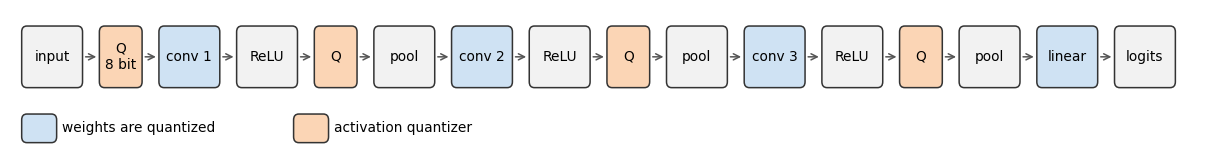

- **Input**: signed, because the normalized image has negative values. Always 8 bits.
- **After each ReLU**: unsigned, asymmetric.
- **Max pooling** needs none. It only picks one of its inputs, so its output is already on the grid.

The quantizer is a small layer that behaves like batch norm: **in training mode it updates its statistics, in eval mode it uses the stored ones**. The statistics are a running minimum and maximum, updated with a moving average:

```
min_val = momentum * min_val + (1 - momentum) * batch_min
max_val = momentum * max_val + (1 - momentum) * batch_max
```

The moving average makes the estimate less sensitive to a single unusual batch than the absolute minimum and maximum would be.

`register_buffer` creates a tensor that belongs to the layer (it is saved and moved to the GPU with it) but is not trained. That is the right place for statistics.

In [ ]:
class ActQuantizer(nn.Module):
    # Fake-quantizes activations and keeps a running estimate of their range
    def __init__(self, bits, signed=False, momentum=0.9):
        super().__init__()
        self.bits = bits
        self.signed = signed
        self.momentum = momentum
        self.enabled = True      # if False, the layer only observes and returns x unchanged
        self.register_buffer("min_val", torch.tensor(0.0))
        self.register_buffer("max_val", torch.tensor(0.0))
        self.register_buffer("initialized", torch.tensor(False))

    def update_range(self, x):
        with torch.no_grad():
            batch_min, batch_max = x.min(), x.max()
            if not self.initialized:
                # the first batch sets the range
                self.min_val.copy_(batch_min)
                self.max_val.copy_(batch_max)
                self.initialized.fill_(True)
            else:
                # TODO (student): update min_val and max_val with the moving average (use .copy_())

    def forward(self, x):
        if self.training:
            self.update_range(x)
        if not self.enabled:
            return x
        if not self.initialized:
            raise RuntimeError("ActQuantizer has no range yet, calibrate the model first.")
        # TODO (student): scale and zero-point from the stored range, then return the fake-quantized x

The layers with weights get a thin wrapper. It keeps the float weights as parameters and fake-quantizes them in every forward pass. For PTQ this gives the same result as `quantize_model_weights`. In Section 4 it will be essential, because training needs the float weights.

`F.conv2d(x, weight, bias, stride, padding)` is the convolution as a function: it takes the weights as an argument, so we can pass the quantized ones.

In [ ]:
class QuantConv2d(nn.Module):
    def __init__(self, conv, bits, per_channel=True):
        super().__init__()
        self.conv = copy.deepcopy(conv)     # holds the float weights and the bias
        self.bits = bits
        self.per_channel = per_channel

    def forward(self, x):
        # TODO (student): fake-quantize self.conv.weight, then convolve with F.conv2d
        #                 (bias, stride and padding come from self.conv)


class QuantLinear(nn.Module):
    def __init__(self, linear, bits, per_channel=True):
        super().__init__()
        self.linear = copy.deepcopy(linear)
        self.bits = bits
        self.per_channel = per_channel

    def forward(self, x):
        w = quantize_weight(self.linear.weight, self.bits, self.per_channel)
        return F.linear(x, w, self.linear.bias)


class QuantSmallCNN(nn.Module):
    # SmallCNN with fake-quantized weights and activations, built from a folded float model
    def __init__(self, folded, w_bits, a_bits, per_channel=True, input_bits=8):
        super().__init__()
        self.input_quant = ActQuantizer(input_bits, signed=True)

        layers = []
        for layer in folded.features:
            if isinstance(layer, nn.Conv2d):
                layers.append(QuantConv2d(layer, w_bits, per_channel))
            elif isinstance(layer, nn.ReLU):
                layers.append(nn.ReLU())
                layers.append(ActQuantizer(a_bits, signed=False))
            elif isinstance(layer, nn.MaxPool2d):
                layers.append(nn.MaxPool2d(2))
            # nn.Identity, the leftover of the folded batch norm, is dropped
        self.features = nn.Sequential(*layers)

        self.classifier = nn.Sequential(
            nn.Flatten(),
            QuantLinear(folded.classifier[1], w_bits, per_channel),
        )

    def forward(self, x):
        return self.classifier(self.features(self.input_quant(x)))


print(QuantSmallCNN(folded_model, w_bits=8, a_bits=8).features)

### 3.9 Calibration and the complete PTQ

`calibrate` has four steps:

1. training mode, so that the quantizers update their ranges (the folded model has no batch norm and no dropout, so nothing else changes),
2. activation quantization off, so that the ranges are measured on clean activations,
3. a few batches through the model, without gradients,
4. activation quantization on again, eval mode. The ranges are now frozen.

The calibration data comes from the **training set**. Calibrating on the test set would be cheating, like tuning hyperparameters on it.

In [ ]:
def set_act_quant(model, enabled):
    # Switches the fake quantization of activations on or off (observation is not affected)
    for module in model.modules():
        if isinstance(module, ActQuantizer):
            module.enabled = enabled


def calibrate(model, loader, num_batches=8):
    model.to(device)
    # TODO (student): the four steps described above


def print_act_ranges(model):
    for name, module in model.named_modules():
        if isinstance(module, ActQuantizer):
            scale, zero_point = compute_qparams(module.min_val, module.max_val, module.bits, module.signed)
            print(f"{name:<14} {module.bits} bits  range [{module.min_val.item():7.3f}, {module.max_val.item():7.3f}]"
                  f"  scale {scale.item():.5f}  zero-point {int(zero_point)}")


def build_ptq(w_bits, a_bits):
    # PTQ: the finished float model, folded, quantized and calibrated. No training.
    model = QuantSmallCNN(fold_model(load_fp(CKPT_FINAL)), w_bits, a_bits)
    calibrate(model, train_loader)
    return model


ptq_8 = build_ptq(w_bits=8, a_bits=8)
print_act_ranges(ptq_8)
print(f"\nfloat model:   {fp_final_acc:.4f}")
print(f"PTQ, 8/8 bits: {evaluate(ptq_8, test_loader):.4f}")

With 8 bits for weights and activations the accuracy is practically that of the float model. That is the normal outcome, and the reason why 8-bit PTQ is the default in industry: a model that is 4 times smaller and runs on integers, for the price of a few seconds of calibration.

Look at the printed ranges as well. The largest activation of a layer is far above what a typical activation looks like, which is exactly the situation from Section 2.7.

Now fewer bits. `W` is the number of bits for the weights, `A` for the activations.

> **Question (answer before running).** `W4/A8` quantizes only the weights to 4 bits, `W8/A4` only the activations. Do you expect the two losses to add up to the loss of `W4/A4`?

In [ ]:
ptq_acc = {}
print(f"float model: {fp_final_acc:.4f}\n")
print(f"{'configuration':<16}{'PTQ accuracy':>14}")
for bits in BITS:
    ptq_acc[bits] = evaluate(build_ptq(bits, bits), test_loader)
    print(f"W{bits}/A{bits:<12}{ptq_acc[bits]:>14.4f}")

print()
for w_bits, a_bits in [(4, 8), (8, 4)]:
    # TODO (student): build the PTQ model for this configuration and evaluate it on the test set
    
    print(f"W{w_bits}/A{a_bits:<12}{acc:>14.4f}")

PTQ holds up well at 8 and 6 bits, starts to lose accuracy at 4, and falls apart below that. At 2 bits the network is not far from guessing, which for 10 classes means 10%.

The reason is that the network was trained with no idea that it would be quantized. Its weights were tuned for full precision, and nothing in the training rewarded solutions that survive rounding. The small errors in every weight and every activation add up from layer to layer, and at 4 bits and below they are no longer small.

More refined PTQ methods exist (smarter ranges, bias correction), and some of them appear in the exercises. Beyond a certain point, however, the real fix is to tell the network about quantization while it is still learning.

## 4. Quantization-aware training (QAT)

### 4.1 The idea

QAT keeps the fake quantization in the network **during training**:

- **Forward pass:** weights and activations are snapped to the grid, so the loss is the loss of the quantized network.
- **Backward pass:** the optimizer updates the float weights underneath, in the direction that lowers that loss.

In this way the network learns float weights that still work after rounding. When the training is over, they are quantized one last time, and the integers are what gets deployed. The float weights were only a tool for training.

Our `QuantSmallCNN` already does the forward part: the wrappers quantize the weights on the fly and keep the float weights as parameters. In principle we could pass it to `train` right now. One obstacle is left.

### 4.2 The problem: the gradient of round

Training needs gradients. Compute the gradient of `fake_quantize` at a few points.

In [ ]:
x = torch.tensor([-1.5, -1.0, -0.5, -0.25, 0.0, 0.25, 0.45, 1.0, 1.5], requires_grad=True)
scale, zero_point = compute_qparams_symmetric(0.6, bits=3)       # 3 bits: the grid goes from -0.8 to 0.6 in steps of 0.2
y = fake_quantize(x, scale, zero_point, *qrange(3, signed=True))

# TODO (student): compute the gradient of y.sum() with respect to x

print("x:        ", [round(v, 3) for v in x.tolist()])
print("fake q(x):", [round(v, 3) for v in y.tolist()])
print("gradient: ", x.grad.tolist())

All zeros. The reason is `round`. It is a staircase: flat everywhere, with jumps in between, so its derivative is zero wherever it exists. By the chain rule, a single zero in the chain wipes out the gradient of everything that comes before it. With this `fake_quantize` no weight would ever receive a gradient, and nothing would be learned.

### 4.3 The straight-through estimator (STE)

The standard way out is a deliberate lie:

```
forward:   y = round(x)
backward:  pretend that y = x, so the gradient is 1
```

The gradient passes "straight through" the rounding. It is not the true gradient, but it points the right way: if the loss wants a larger quantized weight, the float weight grows, and at some point it crosses a rounding threshold and the quantized weight really changes.

To build it we need one new function. **`tensor.detach()`** returns the same values, but cut off from the gradient computation: in the backward pass the result is treated as a constant.

> **Question (answer before running).** What does the next cell print?

In [ ]:
a = torch.tensor(3.0, requires_grad=True)
y = a * a + (a * a).detach()
y.backward()
print("value:   ", y.item())
print("gradient:", a.grad.item())

The value contains both terms (`9 + 9`), the gradient only the first one (`2a = 6`).

Now use it for rounding. We want the *value* of `round(x)` and the *gradient* of `x`. Write `round(x)` as `x` plus a correction, and detach the correction.

The second function in the cell redefines `quantize` with `round_ste` in place of `torch.round`. `fake_quantize`, `quantize_weight` and `ActQuantizer` all call `quantize`, so they switch to the new version automatically. Forward results do not change, only the gradients.

In [ ]:
def round_ste(x):
    # Forward: round(x). Backward: the gradient of x.
    # TODO (student)


def quantize(r, scale, zero_point, qmin, qmax):
    # As in Section 2.6, with round_ste in place of torch.round
    return torch.clamp(round_ste(r / scale) + zero_point, qmin, qmax)


x = torch.linspace(-1.5, 1.5, 601, requires_grad=True)
y = fake_quantize(x, scale, zero_point, *qrange(3, signed=True))
y.sum().backward()
assert torch.equal(y, compute_qparams_symmetric(0.6, 3)[0] * torch.clamp(torch.round(x / scale), -4, 3)), "The forward pass must not change."
assert x.grad.max() == 1, "No gradient passes through, check round_ste."

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].plot(x.tolist(), x.tolist(), color="gray", linestyle=":", label="y = x")
axes[0].plot(x.tolist(), y.tolist(), label="fake_quantize(x)")
axes[0].set_title("forward pass")
axes[0].legend()
axes[0].grid()
axes[1].plot(x.tolist(), x.grad.tolist(), color="tab:orange")
axes[1].set_title("gradient with the straight-through estimator")
axes[1].set_xlabel("x")
axes[1].grid()
plt.show()

The forward pass is the same staircase as before, so nothing changes for PTQ. The gradient, however, is now 1 for values inside the quantization range and 0 for values outside of it.

> **Question.** Where does the zero outside the range come from, and is it reasonable? Think about what `torch.clamp` does to a value far outside the range when that value changes a little.

### 4.4 Running QAT

The recipe, see the figure in Section 1.3:

1. Load the **5-epoch** float model and fold its batch norm.
2. Wrap it in `QuantSmallCNN` and calibrate, so that the activation ranges start from sensible values.
3. Train **5 more epochs** with the plain `train` from Laboratory 1.

`train` needs no change. `model.train()` puts the quantizers in the mode in which they keep updating their ranges, so the ranges follow the activations as the weights change. `model.eval()`, called in `evaluate`, freezes them.

The learning rate is lower than for training from scratch. This is fine-tuning of a trained network, the same argument as for the pretrained teacher in Laboratory 1.

In [ ]:
QAT_EPOCHS = EPOCHS_TOTAL - EPOCHS_FIRST    # the total budget stays the same as for PTQ
QAT_LR = 1e-4


def build_qat(w_bits, a_bits):
    # The starting point for QAT: the first checkpoint, folded, quantized and calibrated
    model = QuantSmallCNN(fold_model(load_fp(CKPT_FIRST)), w_bits, a_bits)
    calibrate(model, train_loader)
    return model


torch.manual_seed(2)
qat_4 = build_qat(w_bits=4, a_bits=4)
print(f"W4/A4 before QAT ({EPOCHS_FIRST}-epoch model, quantized and calibrated): {evaluate(qat_4, test_loader):.4f}")

# Sanity check: with the straight-through estimator the weights receive a gradient
images, labels = next(iter(train_loader))
F.cross_entropy(qat_4(images.to(device)), labels.to(device)).backward()
grad = qat_4.features[0].conv.weight.grad
assert grad is not None and grad.abs().sum() > 0, "No gradient reaches the weights, run the cell with round_ste first."
qat_4.zero_grad()

# TODO (student): train qat_4 for QAT_EPOCHS epochs with the learning rate QAT_LR

qat_4_acc = evaluate(qat_4, test_loader)
print(f"\nfloat, {EPOCHS_FIRST} epochs:                  {fp_first_acc:.4f}")
print(f"float, {EPOCHS_TOTAL} epochs:                 {fp_final_acc:.4f}")
print(f"PTQ W4/A4 (after {EPOCHS_TOTAL} epochs):        {ptq_acc[4]:.4f}")
print(f"QAT W4/A4 ({EPOCHS_FIRST} float + {QAT_EPOCHS} QAT epochs):   {qat_4_acc:.4f}")

Same architecture, same number of bits, same total number of epochs. The only difference is whether the network saw quantization during the last 5 of them.

### 4.5 PTQ against QAT across bit widths

Repeat the experiment for the other bit widths. Three more models are trained for 5 epochs each, so this takes a few minutes.

> **Question (answer before running).** At 8 bits PTQ already matched the float model. What can QAT add there? And at 2 bits, with only four different weight values, will QAT get back to the float accuracy?

In [ ]:
QAT_BITS = [8, 4, 3, 2]
qat_acc = {4: qat_4_acc}
qat_models = {4: qat_4}

for bits in QAT_BITS:
    if bits in qat_acc:
        continue
    print(f"--- QAT W{bits}/A{bits} ---")
    torch.manual_seed(2)
    # TODO (student): build the QAT model for this bit width and train it as in Section 4.4
    
    qat_models[bits] = model
    qat_acc[bits] = evaluate(model, test_loader)

At 8 bits QAT probably ended up slightly *above* the 10-epoch float model.

> **Question.** Quantization did not make the network smarter. What else differed between the two branches in the last 5 epochs? How would you change the experiment to separate the two effects?

### 4.6 What gets deployed

During QAT we trained float weights. The device gets integers: one small integer per weight and one scale per filter. Extract them for the first convolution of the 4-bit model.

In [ ]:
layer = qat_models[4].features[0]
qmin, qmax = qrange(layer.bits, signed=True)

with torch.no_grad():
    w = layer.conv.weight
    scale, zero_point = compute_qparams_symmetric(w.abs().amax(dim=(1, 2, 3), keepdim=True), layer.bits)
    # TODO (student): the integer weights. Use quantize (not fake_quantize) and convert to torch.int8
    # w_int = 
    w_float = w[0, 0].clone()

print("first filter, first input channel, float weights kept during training:")
print(w_float)
print("\nthe same weights as stored on the device:")
print(w_int[0, 0])
print(f"\nscale of this filter: {scale[0].item():.5f}")
print(f"integer values used in the layer: {sorted(w_int.unique().tolist())}")
assert w_int.dtype == torch.int8 and w_int.min() >= qmin and w_int.max() <= qmax

## 5. Results

### 5.1 Accuracy against size

The size of the weights is computed as in Laboratory 1, now with a configurable number of bits. The 122 biases are counted with 32 bits.

In [ ]:
def weights_size_kb(model, w_bits):
    layers = [m for m in model.modules() if isinstance(m, (nn.Conv2d, nn.Linear))]
    bits = sum(m.weight.numel() * w_bits + m.bias.numel() * 32 for m in layers)
    return bits / 8 / 1024


float_size = weights_size_kb(folded_model, 32)

print(f"{'model':<26}{'size [KB]':>10}{'accuracy':>10}")
print(f"{'float32, ' + str(EPOCHS_FIRST) + ' epochs':<26}{float_size:>10.1f}{fp_first_acc:>10.4f}")
print(f"{'float32, ' + str(EPOCHS_TOTAL) + ' epochs':<26}{float_size:>10.1f}{fp_final_acc:>10.4f}")
print()
print(f"{'configuration':<16}{'size [KB]':>10}{'PTQ':>10}{'QAT':>10}")
for bits in BITS:
    qat = f"{qat_acc[bits]:.4f}" if bits in qat_acc else "-"
    print(f"W{bits}/A{bits:<12}{weights_size_kb(folded_model, bits):>10.1f}{ptq_acc[bits]:>10.4f}{qat:>10}")

plt.figure(figsize=(7, 4))
plt.plot(BITS, [ptq_acc[b] for b in BITS], "o-", label=f"PTQ ({EPOCHS_TOTAL} float epochs)")
plt.plot(QAT_BITS, [qat_acc[b] for b in QAT_BITS], "s-", label=f"QAT ({EPOCHS_FIRST} float + {QAT_EPOCHS} QAT epochs)")
plt.axhline(fp_final_acc, color="gray", linestyle="--", label=f"float32, {EPOCHS_TOTAL} epochs")
plt.axhline(fp_first_acc, color="gray", linestyle=":", label=f"float32, {EPOCHS_FIRST} epochs")
plt.xlabel("bits for weights and activations")
plt.ylabel("test accuracy")
plt.xticks(BITS)
plt.legend()
plt.grid()
plt.show()

As in Laboratory 1, every model was trained once, so differences of a few tenths of a percent are noise. The differences at 4 bits and below are much larger than that.

### 5.2 Back to the devices

The table of microcontrollers from Laboratory 1, now with the quantized models. It only checks the weights against flash.

In [ ]:
# name: (flash in KB, RAM in KB)
platforms = {
    "Arduino Uno (ATmega328P)": (32, 2),
    "STM32F407":                (1024, 192),
    "ESP32-P4 (16 MB ext. flash)": (16384, 768),
}

print(f"{'platform':<30}" + "".join(f"{str(b) + ' bit':>9}" for b in [32] + BITS))
for name, (flash, ram) in platforms.items():
    row = "".join(f"{'yes' if weights_size_kb(folded_model, b) < flash else 'no':>9}" for b in [32] + BITS)
    print(f"{name:<30}{row}")

# The largest activation tensor is the output of the first convolution: 16 channels of 32x32
largest_activation = 16 * 32 * 32
print(f"\nlargest activation tensor: {largest_activation} values")
for bits in [32, 8, 4, 2]:
    # TODO (student): the RAM in KB that this tensor needs at the given number of bits per value
    # ram_kb = 
    print(f"  at {bits:>2} bits: {ram_kb:6.1f} KB of RAM")

> **Question.** The weights of the 4-bit model fit into the flash of an Arduino Uno. Would the network run there?

### 5.3 Exercises

1. **Better calibration.** Replace the batch maximum in `ActQuantizer` by a percentile (for example the 99.9th, `torch.quantile`) and repeat the PTQ sweep. Where does it help? Connect the result to Section 2.7.
2. **First and last layer.** Keep the first and the last layer at 8 bits and use fewer bits only in between. Repeat QAT at 2 and 3 bits. What comes back, and what does it cost in size?
3. **Power-of-two scales.** Round every scale to the nearest power of two, so that multiplying by it is a bit shift (this is fixed point from Section 2.2). What does it cost with PTQ at 8 and at 4 bits?
4. **Calibration data.** Run PTQ at 4 bits with 1, 8 and 64 calibration batches. What changes?
5. **Learning rate.** Run QAT at 4 bits with `lr=1e-3` and `lr=1e-5`. What happens, and why?
6. **Distillation plus QAT.** Use the ResNet-18 teacher and `distillation_loss` from Laboratory 1 during the QAT epochs of a 2-bit or 3-bit model. Does the teacher help?

### 5.4 Common pitfalls

- Quantizing without folding batch norm first: the quantized weights are then not the weights the device uses.
- Folding batch norm in training mode, or continuing normal training after folding.
- Calibrating on the test set, or not calibrating at all.
- Evaluating in training mode, so the activation ranges move while you measure.
- Forgetting the straight-through estimator: the code runs without error and the loss does not go down.
- A learning rate for QAT as high as for training from scratch.
- Comparing PTQ and QAT with different training budgets.
- Reporting the model size from the simulation. A fake-quantized model in PyTorch is still float32. The saving is real once the integer weights are exported.

### 5.6 Summary

- A quantized number is an integer `q`. The real value it stands for is `S * (q - Z)`: `S` is the size of one step, `Z` the integer that stands for zero.
- Every quantizer makes rounding and clipping errors. Choosing the range trades one against the other.
- Weights: symmetric, per channel. Activations: asymmetric, with a range found by calibration. Batch norm: folded into the convolution first.
- PTQ needs a trained model and a few unlabeled samples. At 8 bits it is usually enough.
- QAT simulates quantization during training and uses the straight-through estimator to get gradients through the rounding. It needs training data and time, and it makes low bit widths usable.
- Fewer bits mean less flash, less RAM and cheaper arithmetic. The price is accuracy, and it must be measured.

### 5.7 Further reading

- B. Jacob et al., *Quantization and Training of Neural Networks for Efficient Integer-Arithmetic-Only Inference*, 2017, arXiv:1712.05877.
- R. Krishnamoorthi, *Quantizing deep convolutional networks for efficient inference: A whitepaper*, 2018, arXiv:1806.08342.
- M. Nagel et al., *A White Paper on Neural Network Quantization*, 2021, arXiv:2106.08295.
- Y. Bengio, N. Léonard, A. Courville, *Estimating or Propagating Gradients Through Stochastic Neurons for Conditional Computation*, 2013, arXiv:1308.3432 (the straight-through estimator).
- A. Gholami et al., *A Survey of Quantization Methods for Efficient Neural Network Inference*, 2021, arXiv:2103.13630.

## 6. Optional: a layer on integers only

Not required for the laboratory. Read it if you are curious how a quantized layer is really executed on a microcontroller or an FPGA. The scheme comes from the paper by Jacob et al. (Google), and it is what TensorFlow Lite and most integer inference engines implement.

### 6.1 Notation and the starting point

| symbol | meaning |
|---|---|
| `x`, `w`, `b`, `y` | real input, weight, bias and output of a layer |
| `q_x`, `q_w`, `q_b`, `q_y` | the integers that are stored for them |
| `S_x`, `S_w`, `S_b`, `S_y` | their scales |
| `Z_x`, `Z_y` | the zero-points of the input and the output. Weights are symmetric, so `Z_w = 0` |
| `acc` | the accumulator: the integer in which the sum is collected |

A layer computes `y = sum(w * x) + b`. Replace every real value by what its integer stands for, `S * (q - Z)`:

```
S_y * (q_y - Z_y) = S_w * S_x * sum( q_w * (q_x - Z_x) ) + b
```

The weights and activations are integers already. Three things in this line are still not integer-friendly: the float bias `b`, the subtraction `q_x - Z_x` in front of every multiplication, and the float scales. The three steps below remove them one by one.

### 6.2 Step 1: the bias becomes an integer

The sum is an integer with the scale `S_w * S_x`. To add the bias to it as an integer, the bias must have the same scale. So the bias gets no scale of its own:

```
S_b = S_w * S_x        Z_b = 0        q_b = round( b / (S_w * S_x) )
```

`S_w * S_x` is a tiny step, so `q_b` can be large. It is stored with 32 bits, like the accumulator.

**Gain:** adding the bias is no extra operation, the accumulator simply starts at `q_b` instead of 0. At 32 bits the rounding error of the bias is negligible, which is why we could leave the bias in float in Sections 3 and 4.

### 6.3 Step 2: the zero-point moves into the bias

Multiply out the bracket:

```
sum( q_w * (q_x - Z_x) ) = sum( q_w * q_x ) - Z_x * sum( q_w )
```

The second term does not contain the input. `Z_x` and the weights are known before the device is switched on, so `Z_x * sum(q_w)` is a constant, one per output channel. A constant that is added to the sum is a bias, so it is merged with the bias:

```
q_b_folded = q_b - Z_x * sum( q_w )
acc        = sum( q_w * q_x ) + q_b_folded
```

**Gain:** no subtraction in front of any multiplication. For one image `SmallCNN` performs about 2.8 million multiplications, and as many subtractions are replaced by 122 constants computed once on a PC. The multiplier inputs also stay narrow: `q_x - Z_x` would need 9 bits for an 8-bit input.

This is the real reason for `Z_w = 0`. With a zero-point on the weights, a term `Z_w * sum(q_x)` would remain. It contains the input, so it could not be precomputed.

One consequence: a convolution pads its input with the real value 0, and the integer for real 0 is `Z_x`. The stored input must therefore be padded with `Z_x`, not with the integer 0.

### 6.4 Step 3: back to the scale of the output

The accumulator has the scale `S_w * S_x`. The next layer expects integers with the scale `S_y` and the zero-point `Z_y`:

```
q_y = clamp( round( M * acc ) + Z_y, q_min, q_max )        M = S_w * S_x / S_y
```

`M` is the last real number in the layer. It is a constant, so it is stored as an integer `M0` and a shift `n` with `M ≈ M0 * 2^-n`.

**Gain:** the float multiplication becomes one integer multiplication and one bit shift. And if the output is unsigned with `Z_y = 0`, the clamp at 0 removes everything negative, so ReLU costs nothing.

### 6.5 All three steps on a small example

In [ ]:
x = torch.tensor([0.2, -0.4, 0.7, -0.9])
w = torch.tensor([0.5, -0.3, 0.1, -0.8])
b = torch.tensor(0.35)
y_float = (w * x).sum() + b

s_x, z_x = compute_qparams(x.min(), x.max(), 8, signed=False)
s_w, _ = compute_qparams_symmetric(w.abs().max(), 8)
q_x = quantize(x, s_x, z_x, *qrange(8, signed=False)).to(torch.int32)
q_w = quantize(w, s_w, 0, *qrange(8, signed=True)).to(torch.int32)
z_x = z_x.to(torch.int32)

# TODO (student): Step 1, the bias as a 32-bit integer
# q_b = 

# TODO (student): Step 2, the zero-point of the input folded into the bias
# q_b_folded = 

# What the device computes: no zero-point anywhere in the sum
acc = (q_w * q_x).sum() + q_b_folded
assert acc == (q_w * (q_x - z_x)).sum() + q_b, "The folded form must give the same accumulator."

# Step 3: back to an 8-bit unsigned output. We assume the output range [-2, 2];
# in a network it comes from calibration.
s_y, z_y = compute_qparams(-2.0, 2.0, 8, signed=False)
M = (s_w * s_x / s_y).item()
n = 24
M0 = round(M * 2 ** n)
q_y = ((acc.item() * M0 + (1 << (n - 1))) >> n) + int(z_y)      # integer multiplication, rounding, shift

print(f"q_b = {q_b.item()}, sum(q_w) = {q_w.sum().item()}, Z_x = {int(z_x)}  ->  q_b_folded = {q_b_folded.item()}")
print(f"accumulator = {acc.item()}")
print(f"M = {M:.6f}  ->  M0 = {M0}, n = {n}")
print(f"q_y = {q_y}")
print(f"\nfloat result:   {y_float.item():.5f}")
print(f"integer result: {(s_y * (q_y - z_y)).item():.5f}   (one output step is {s_y.item():.5f})")

What is left on the device for every output value: integer multiplications and additions, one more multiplication, one shift, one clamp. No float anywhere.

Things to think about:

- Why is the bias stored with 32 bits when weights and inputs have 8? What would go wrong with an 8-bit bias that has its own scale?
- How many bits does the accumulator need for a 3x3 convolution with 64 input channels, 8-bit inputs and 8-bit weights?
- What goes wrong at the border of the image if the stored input is padded with the integer 0?